# EDA — Classificação de condições de falha por sinais de vibração

Análise exploratória da base da máquina rotativa deste projeto. O objetivo é entender a estrutura, qualidade e comportamento dos sinais medidos antes de qualquer modelo. **Este notebook não treina Machine Learning.**

Execute as células em ordem, como no Colab. O notebook contém a leitura dos LVMs, o inventário, o cálculo das features e as análises; não depende de módulos Python do projeto. O processamento completo dos 1.200 arquivos pode levar alguns minutos.


## 1. Importação das bibliotecas e configuração da análise

As dependências são Pandas, NumPy, Matplotlib, Seaborn e SciPy. Os dados brutos devem estar em `data/raw`, organizados nas pastas de condição e rotação do dataset Zenodo. Se estiver usando Colab, ajuste `PROJECT_ROOT` para a pasta do projeto montada ou enviada para a sessão.


In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.integrate import trapezoid
from scipy.signal import periodogram
from scipy.stats import kurtosis, skew

try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda iterable, **kwargs: iterable

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 6)

# Detecta a raiz quando o notebook é aberto na raiz do projeto ou em notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw").exists() and (PROJECT_ROOT.parent / "data" / "raw").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURE_DIR = PROJECT_ROOT / "docs" / "figures" / "eda"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

CONDITIONS = [
    "Baseline", "Bearing", "Bearing+Unbalance",
    "Misalignment_NDE", "Unbalance_DE", "Unbalance_NDE",
]
ROTATIONS_HZ = [10, 20, 30, 40]
FS_HZ = 6000
COLUMNS = [
    "point", "time", "trigger",
    "acc_de_h", "acc_de_v", "acc_nde_h", "acc_nde_v",
    "vel_de_h", "vel_de_v", "vel_nde_h", "vel_nde_v",
]
ACCELERATION_COLUMNS = ["acc_de_h", "acc_de_v", "acc_nde_h", "acc_nde_v"]
VELOCITY_COLUMNS = ["vel_de_h", "vel_de_v", "vel_nde_h", "vel_nde_v"]
SIGNAL_COLUMNS = ACCELERATION_COLUMNS + VELOCITY_COLUMNS
FREQUENCY_BANDS_HZ = {
    "0_100hz": (0, 100),
    "100_500hz": (100, 500),
    "500_1500hz": (500, 1500),
    "1500_3000hz": (1500, 3000),
}
print("Raiz do projeto:", PROJECT_ROOT)
print("Diretório de dados brutos:", RAW_DIR)
print("Arquivos LVM encontrados:", len(list(RAW_DIR.rglob("*.lvm"))))


Raiz do projeto: D:\PROJETOS\vibration-fault-classifier
Diretório de dados brutos: D:\PROJETOS\vibration-fault-classifier\data\raw
Arquivos LVM encontrados: 1200


## 2. Leitura dos arquivos LVM e criação do inventário

Cada LVM contém dois cabeçalhos LabVIEW seguidos pelas colunas numéricas. A condição e a rotação são inferidas pelas pastas do arquivo. O inventário registra também o caminho e o tamanho para manter a rastreabilidade.


In [2]:
def read_lvm(file_path):
    # Lê os 11 campos numéricos do arquivo LVM deste dataset.
    file_path = Path(file_path)
    with file_path.open("r", encoding="utf-8-sig", errors="replace") as stream:
        lines = stream.readlines()
    header_ends = [i for i, line in enumerate(lines) if "***End_of_Header***" in line]
    if len(header_ends) < 2:
        raise ValueError(f"Não encontrei os dois cabeçalhos em {file_path}")

    data_start = header_ends[1] + 2  # pula a linha de nomes das colunas
    frame = pd.read_csv(
        file_path, sep="\t", skiprows=data_start, header=None,
        usecols=range(11), names=COLUMNS,
    )
    for column in COLUMNS:
        frame[column] = pd.to_numeric(frame[column], errors="coerce")
    return frame.dropna(how="all").reset_index(drop=True)

def build_inventory(raw_dir):
    rows = []
    for file_path in sorted(Path(raw_dir).rglob("*.lvm")):
        relative_parts = file_path.relative_to(raw_dir).parts
        condition = next((part for part in relative_parts if part in CONDITIONS), None)
        rotation = next(
            (int(match.group(1)) for part in relative_parts[:-1]
             if (match := re.fullmatch(r"(\d+)Hz", part))),
            None,
        )
        if condition is None or rotation is None:
            raise ValueError(f"Condição ou rotação não identificada: {file_path}")
        rows.append({
            "condition": condition,
            "rotation_hz": rotation,
            "file_name": file_path.name,
            "relative_path": file_path.relative_to(PROJECT_ROOT).as_posix(),
            "size_bytes": file_path.stat().st_size,
        })
    return rows

inventory_rows = build_inventory(RAW_DIR)
inventory = pd.DataFrame(inventory_rows)
display(inventory.head())
print("Dimensões do inventário:", inventory.shape)


,condition,rotation_hz,file_name,relative_path,size_bytes
0,Baseline,10,Normal_10Hz_001.lvm,data/raw/Baseline/Baseline/10Hz/Normal_10Hz_00...,3867472
1,Baseline,10,Normal_10Hz_002.lvm,data/raw/Baseline/Baseline/10Hz/Normal_10Hz_00...,3868148
2,Baseline,10,Normal_10Hz_003.lvm,data/raw/Baseline/Baseline/10Hz/Normal_10Hz_00...,3866939
3,Baseline,10,Normal_10Hz_004.lvm,data/raw/Baseline/Baseline/10Hz/Normal_10Hz_00...,3867744
4,Baseline,10,Normal_10Hz_005.lvm,data/raw/Baseline/Baseline/10Hz/Normal_10Hz_00...,3868197


Dimensões do inventário: (1200, 5)


## 3. Dimensões e distribuição das condições

Verificamos se as seis condições e as quatro velocidades têm a contagem esperada antes de interpretar as features.


In [3]:
class_counts = (
    inventory.groupby(["condition", "rotation_hz"])
    .size().unstack(fill_value=0)
    .reindex(index=CONDITIONS, columns=ROTATIONS_HZ, fill_value=0)
)
display(class_counts)
print("Total de arquivos:", len(inventory))
print("Caminhos duplicados:", int(inventory.relative_path.duplicated().sum()))


rotation_hz,10,20,30,40
condition,,,,
Baseline,50,50,50,50
Bearing,50,50,50,50
Bearing+Unbalance,50,50,50,50
Misalignment_NDE,50,50,50,50
Unbalance_DE,50,50,50,50
Unbalance_NDE,50,50,50,50


Total de arquivos: 1200
Caminhos duplicados: 0


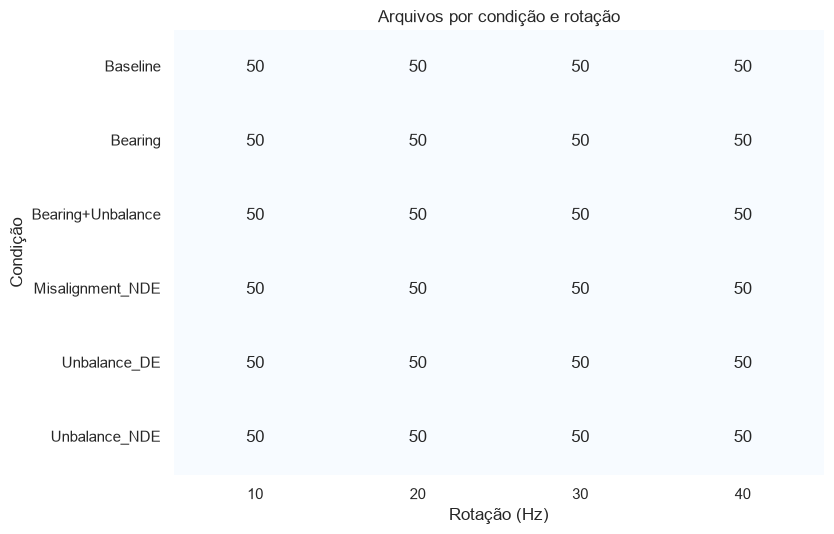

In [4]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.heatmap(class_counts, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(title="Arquivos por condição e rotação", xlabel="Rotação (Hz)", ylabel="Condição")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "class_distribution.png", dpi=170)
plt.show()


## 4. Inspeção de um sinal e das variáveis

O loader converte as 11 colunas em valores numéricos. A tabela abaixo permite conferir uma amostra real antes do processamento completo.


In [5]:
sample_path = PROJECT_ROOT / inventory_rows[0]["relative_path"]
sample_df = read_lvm(sample_path)
print("Arquivo:", sample_path.relative_to(PROJECT_ROOT))
print("Dimensões:", sample_df.shape)
display(sample_df.head())
display(sample_df.dtypes.rename("dtype").to_frame())
display(sample_df.describe().T)


Arquivo: data\raw\Baseline\Baseline\10Hz\Normal_10Hz_001.lvm
Dimensões: (36000, 11)


,point,time,trigger,acc_de_h,acc_de_v,acc_nde_h,acc_nde_v,vel_de_h,vel_de_v,vel_nde_h,vel_nde_v
0,0.0,0.000000,1.0,-0.851011,0.152313,0.079080,0.097078,-0.139750,0.025012,0.012986,0.015942
1,1.0,0.000167,1.0,-0.662867,0.153815,0.032163,0.036300,-0.244465,0.049530,0.017883,0.021431
2,2.0,0.000333,1.0,-0.293700,0.029187,-0.023012,-0.058244,-0.285395,0.052846,0.013569,0.011224
3,3.0,0.000500,1.0,0.051856,-0.155502,-0.191165,-0.047364,-0.268260,0.025712,-0.018239,0.003098
4,4.0,0.000667,1.0,0.296218,-0.210308,-0.343929,-0.087133,-0.211382,-0.009640,-0.074197,-0.011324


,dtype
point,float64
time,float64
trigger,float64
acc_de_h,float64
acc_de_v,float64
acc_nde_h,float64
acc_nde_v,float64
vel_de_h,float64
vel_de_v,float64
vel_nde_h,float64


,count,mean,std,min,25%,50%,75%,max
point,36000.0,1.799950e+04,10392.449182,0.000000,8999.750000,17999.500000,26999.250000,35999.000000
time,35735.0,2.977833e+00,1.719325,0.000000,1.488917,2.977833,4.466750,5.955667
trigger,36000.0,3.582500e-01,0.479493,0.000000,0.000000,0.000000,1.000000,1.000000
acc_de_h,36000.0,-1.583333e-09,0.216375,-1.912413,-0.101433,-0.013358,0.086711,1.726412
acc_de_v,36000.0,3.134519e-09,0.125441,-0.875489,-0.065410,-0.001594,0.062972,0.882060
acc_nde_h,36000.0,4.722222e-10,0.187876,-1.259385,-0.083818,0.000259,0.083209,1.500120
acc_nde_v,36000.0,-1.627549e-09,0.092951,-0.813847,-0.045864,-0.000843,0.044929,0.779896
vel_de_h,35735.0,-3.897276e-04,0.238823,-0.645676,-0.209848,-0.027087,0.195499,0.944282
vel_de_v,35735.0,6.322842e-04,0.136375,-0.429546,-0.105778,0.017527,0.112936,0.411099
vel_nde_h,35735.0,3.686769e-04,0.137980,-0.646804,-0.083753,0.006671,0.088710,0.745575


## 5. Checagem de qualidade e extração de estatísticas

Cada arquivo é lido uma única vez. Para os oito canais de vibração calculamos estatísticas temporais e RMS espectral em bandas amplas. Também registramos valores ausentes e se alguma ausência ocorre antes do último valor válido. As ausências esperadas no fim de `time` e velocidade não são preenchidas artificialmente.


In [6]:
TIME_FEATURES = [
    "mean", "std", "variance", "rms", "kurtosis",
    "skewness", "peak_abs", "peak_to_peak", "crest_factor",
]
FREQUENCY_FEATURES = [f"fft_rms_{band}" for band in FREQUENCY_BANDS_HZ]

def time_features(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return {name: np.nan for name in TIME_FEATURES}
    rms = float(np.sqrt(np.mean(x ** 2)))
    return {
        "mean": float(np.mean(x)),
        "std": float(np.std(x, ddof=1)) if x.size > 1 else 0.0,
        "variance": float(np.var(x, ddof=1)) if x.size > 1 else 0.0,
        "rms": rms,
        "kurtosis": float(kurtosis(x, fisher=True, bias=False)) if x.size > 3 else 0.0,
        "skewness": float(skew(x, bias=False)) if x.size > 2 else 0.0,
        "peak_abs": float(np.max(np.abs(x))),
        "peak_to_peak": float(np.ptp(x)),
        "crest_factor": float(np.max(np.abs(x)) / rms) if rms else 0.0,
    }

def frequency_band_features(values):
    x = np.asarray(values, dtype=float)
    x = x[np.isfinite(x)]
    if x.size < 4:
        return {name: np.nan for name in FREQUENCY_FEATURES}
    frequency, power_density = periodogram(
        x, fs=FS_HZ, window="hann", detrend="constant", scaling="density"
    )
    result = {}
    for band, (lower_hz, upper_hz) in FREQUENCY_BANDS_HZ.items():
        mask = (frequency >= lower_hz) & (frequency < upper_hz)
        band_power = trapezoid(power_density[mask], frequency[mask])
        result[f"fft_rms_{band}"] = float(np.sqrt(max(float(band_power), 0.0)))
    return result

feature_rows = []
quality_rows = []
for item in tqdm(inventory_rows, total=len(inventory_rows), desc="Lendo LVMs"):
    frame = read_lvm(PROJECT_ROOT / item["relative_path"])
    row = {key: item[key] for key in ("condition", "rotation_hz", "file_name", "relative_path", "size_bytes")}
    row["rows"] = len(frame)
    for channel in SIGNAL_COLUMNS:
        values = frame[channel]
        for name, value in time_features(values).items():
            row[f"{channel}_{name}"] = value
        for name, value in frequency_band_features(values).items():
            row[f"{channel}_{name}"] = value
    feature_rows.append(row)

    quality = {key: row[key] for key in ("condition", "rotation_hz", "file_name", "relative_path", "rows")}
    for column in COLUMNS:
        missing = frame[column].isna()
        last_valid = frame[column].last_valid_index()
        quality[f"missing_{column}"] = int(missing.sum())
        quality[f"valid_{column}"] = int((~missing).sum())
        quality[f"interior_missing_{column}"] = (
            int(missing.iloc[:last_valid + 1].sum()) if last_valid is not None else int(missing.sum())
        )
    quality_rows.append(quality)

features = pd.DataFrame(feature_rows)
quality = pd.DataFrame(quality_rows)

# Resumo por condição, rotação, canal e feature.
summary_rows = []
for channel in SIGNAL_COLUMNS:
    for feature_name in TIME_FEATURES + FREQUENCY_FEATURES:
        column = f"{channel}_{feature_name}"
        grouped = features.groupby(["condition", "rotation_hz"])[column]
        for (condition, rotation), values in grouped:
            summary_rows.append({
                "condition": condition, "rotation_hz": int(rotation),
                "channel": channel, "feature": feature_name,
                "mean": float(values.mean()), "median": float(values.median()),
                "std": float(values.std()), "q25": float(values.quantile(0.25)),
                "q75": float(values.quantile(0.75)),
            })
feature_summary = pd.DataFrame(summary_rows)

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
features.to_csv(PROCESSED_DIR / "eda_features.csv", index=False)
quality.to_csv(PROCESSED_DIR / "eda_quality.csv", index=False)
feature_summary.to_csv(PROCESSED_DIR / "eda_group_summary.csv", index=False)
print("Features:", features.shape, "| qualidade:", quality.shape, "| resumo:", feature_summary.shape)


Lendo LVMs:   0%|          | 0/1200 [00:00<?, ?it/s]

Features: (1200, 110) | qualidade: (1200, 38) | resumo: (2496, 9)


## 6. Ausências, inconsistências e possíveis anomalias

As contagens de ausências são apresentadas por coluna. `interior_missing` conta valores ausentes até o último valor válido; zero significa que as ausências estão somente no trecho final. Para triagem de extremos, usamos o modified z-score do RMS dentro do mesmo grupo condição-rotação. A marcação indica arquivo para inspeção, não defeito confirmado.


In [7]:
missing_cols = [c for c in quality.columns if c.startswith("missing_")]
interior_cols = [c for c in quality.columns if c.startswith("interior_missing_")]
missing_summary = pd.DataFrame({
    "missing_total": quality[missing_cols].sum().to_numpy(),
    "interior_missing_total": quality[interior_cols].sum().to_numpy(),
}, index=COLUMNS)
display(missing_summary)
print("Linhas por arquivo:")
display(quality.rows.value_counts().rename_axis("rows").to_frame("files"))
print("Resumo do número de ausências em time por arquivo:")
display(quality.missing_time.describe().to_frame())


,missing_total,interior_missing_total
point,0,0
time,132829,0
trigger,0,0
acc_de_h,0,0
acc_de_v,0,0
acc_nde_h,0,0
acc_nde_v,0,0
vel_de_h,132829,0
vel_de_v,132829,0
vel_nde_h,132829,0


Linhas por arquivo:


,files
rows,
36000,1200


Resumo do número de ausências em time por arquivo:


,missing_time
count,1200.000000
mean,110.690833
std,89.930481
min,1.000000
25%,40.000000
50%,72.000000
75%,177.250000
max,310.000000


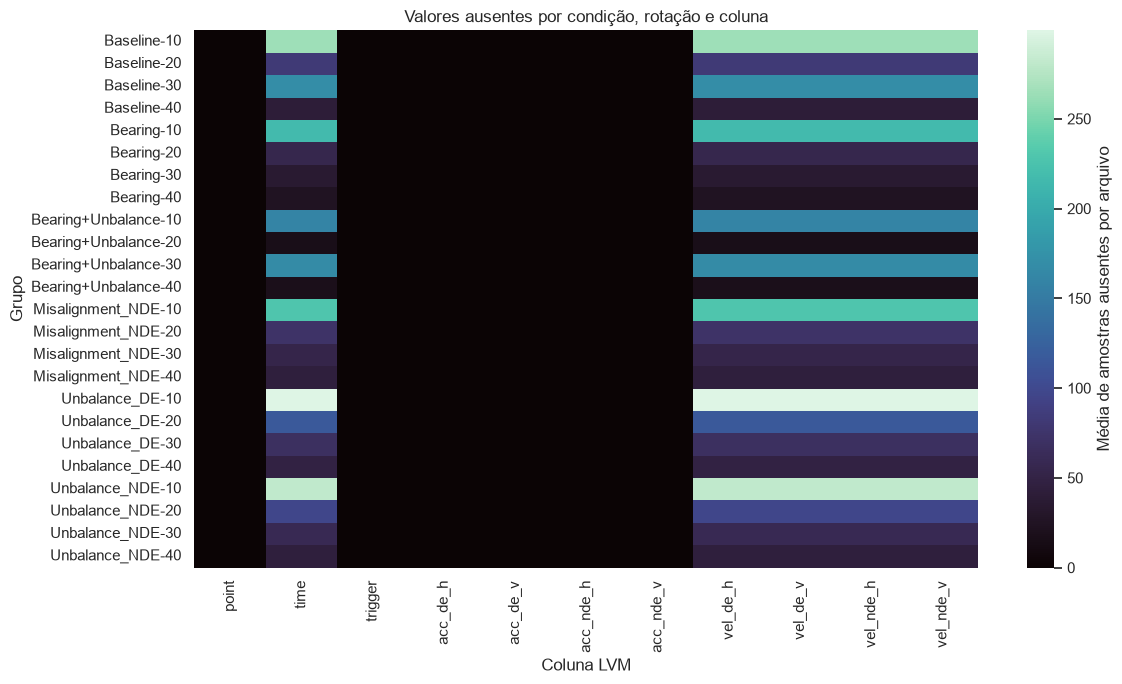

In [8]:
missing_by_group = quality.groupby(["condition", "rotation_hz"])[missing_cols].mean()
missing_by_group.columns = [column.removeprefix("missing_") for column in missing_by_group.columns]
fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(missing_by_group, cmap="mako", ax=ax,
            cbar_kws={"label": "Média de amostras ausentes por arquivo"})
ax.set(title="Valores ausentes por condição, rotação e coluna", xlabel="Coluna LVM", ylabel="Grupo")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "missing_values.png", dpi=170)
plt.show()


In [9]:
def add_rms_outlier_flags(data):
    data = data.copy()
    for channel in SIGNAL_COLUMNS:
        rms_column = f"{channel}_rms"
        flag_column = f"{channel}_rms_outlier"
        data[flag_column] = False
        for _, indexes in data.groupby(["condition", "rotation_hz"]).groups.items():
            values = data.loc[indexes, rms_column]
            median = values.median()
            mad = (values - median).abs().median()
            if pd.notna(mad) and mad > 0:
                modified_z = 0.6745 * (values - median) / mad
                data.loc[indexes, flag_column] = modified_z.abs() > 3.5
    return data

features = add_rms_outlier_flags(features)
features.to_csv(PROCESSED_DIR / "eda_features.csv", index=False)
outlier_columns = [f"{channel}_rms_outlier" for channel in SIGNAL_COLUMNS]
display(features[outlier_columns].sum().sort_values(ascending=False).rename("candidate flags").to_frame())
candidates = features.loc[features[outlier_columns].any(axis=1),
                          ["condition", "rotation_hz", "file_name", "relative_path", "acc_de_h_rms"]]
print("Arquivos com ao menos uma marcação:", len(candidates))
display(candidates.head(20))


,candidate flags
acc_de_h_rms_outlier,17
acc_nde_h_rms_outlier,17
vel_nde_h_rms_outlier,12
vel_de_h_rms_outlier,12
vel_de_v_rms_outlier,9
acc_de_v_rms_outlier,9
vel_nde_v_rms_outlier,9
acc_nde_v_rms_outlier,2


Arquivos com ao menos uma marcação: 51


,condition,rotation_hz,file_name,relative_path,acc_de_h_rms
150,Baseline,40,Normal_40Hz_001.lvm,data/raw/Baseline/Baseline/40Hz/Normal_40Hz_00...,2.047131
151,Baseline,40,Normal_40Hz_002.lvm,data/raw/Baseline/Baseline/40Hz/Normal_40Hz_00...,2.075942
152,Baseline,40,Normal_40Hz_003.lvm,data/raw/Baseline/Baseline/40Hz/Normal_40Hz_00...,2.119053
443,Bearing+Unbalance,10,RolamDesbal_10Hz_044.lvm,data/raw/Bearing+Unbalance/Defeito Rol e Desba...,0.267885
450,Bearing+Unbalance,20,RolamDesbal_20Hz_001.lvm,data/raw/Bearing+Unbalance/Defeito Rol e Desba...,0.433440
500,Bearing+Unbalance,30,RolamDesbal_30Hz_001.lvm,data/raw/Bearing+Unbalance/Defeito Rol e Desba...,1.346959
501,Bearing+Unbalance,30,RolamDesbal_30Hz_002.lvm,data/raw/Bearing+Unbalance/Defeito Rol e Desba...,1.342034
502,Bearing+Unbalance,30,RolamDesbal_30Hz_003.lvm,data/raw/Bearing+Unbalance/Defeito Rol e Desba...,1.356588
543,Bearing+Unbalance,30,RolamDesbal_30Hz_044.lvm,data/raw/Bearing+Unbalance/Defeito Rol e Desba...,1.309111
544,Bearing+Unbalance,30,RolamDesbal_30Hz_045.lvm,data/raw/Bearing+Unbalance/Defeito Rol e Desba...,1.326064


## 7. Estatísticas e comparação entre condições

RMS, desvio padrão, variância, curtose, assimetria e picos são comparados por canal, condição e rotação. As caixas ocultam pontos extremos para melhorar a leitura; os candidatos a outlier estão disponíveis na etapa anterior.


In [10]:
display(features.shape)
selected_features = [
    "acc_de_h_mean", "acc_de_h_std", "acc_de_h_variance", "acc_de_h_rms",
    "acc_de_h_kurtosis", "acc_de_h_skewness", "acc_de_h_peak_abs",
    "acc_de_h_peak_to_peak", "acc_de_h_crest_factor",
]
display(features[features.rotation_hz.eq(20)].groupby("condition")[selected_features].median().reindex(CONDITIONS).round(3))


(1200, 118)

,acc_de_h_mean,acc_de_h_std,acc_de_h_variance,acc_de_h_rms,acc_de_h_kurtosis,acc_de_h_skewness,acc_de_h_peak_abs,acc_de_h_peak_to_peak,acc_de_h_crest_factor
condition,,,,,,,,,
Baseline,0.0,0.685,0.469,0.685,1.159,0.139,3.729,7.285,5.478
Bearing,0.0,0.395,0.156,0.395,0.248,0.056,1.906,3.649,4.821
Bearing+Unbalance,-0.0,0.437,0.191,0.437,1.167,0.074,2.413,4.523,5.469
Misalignment_NDE,0.0,1.719,2.957,1.719,0.850,-0.391,7.972,14.236,4.410
Unbalance_DE,-0.0,1.227,1.506,1.227,0.850,0.268,5.341,10.052,4.355
Unbalance_NDE,-0.0,1.334,1.779,1.334,1.220,0.135,5.961,11.505,4.455


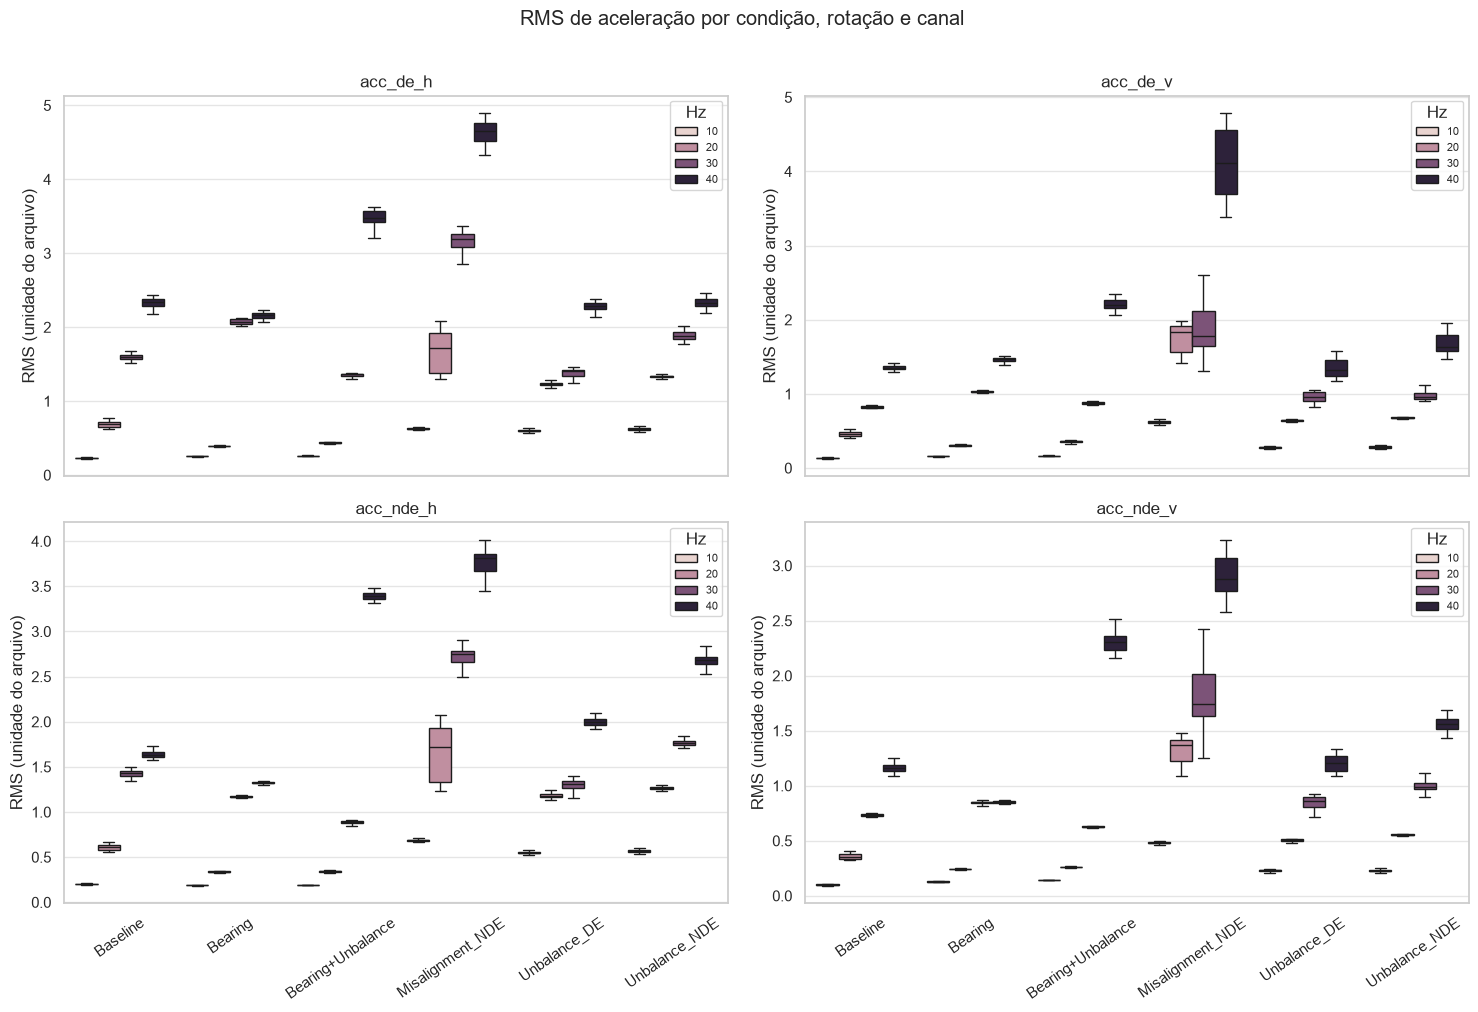

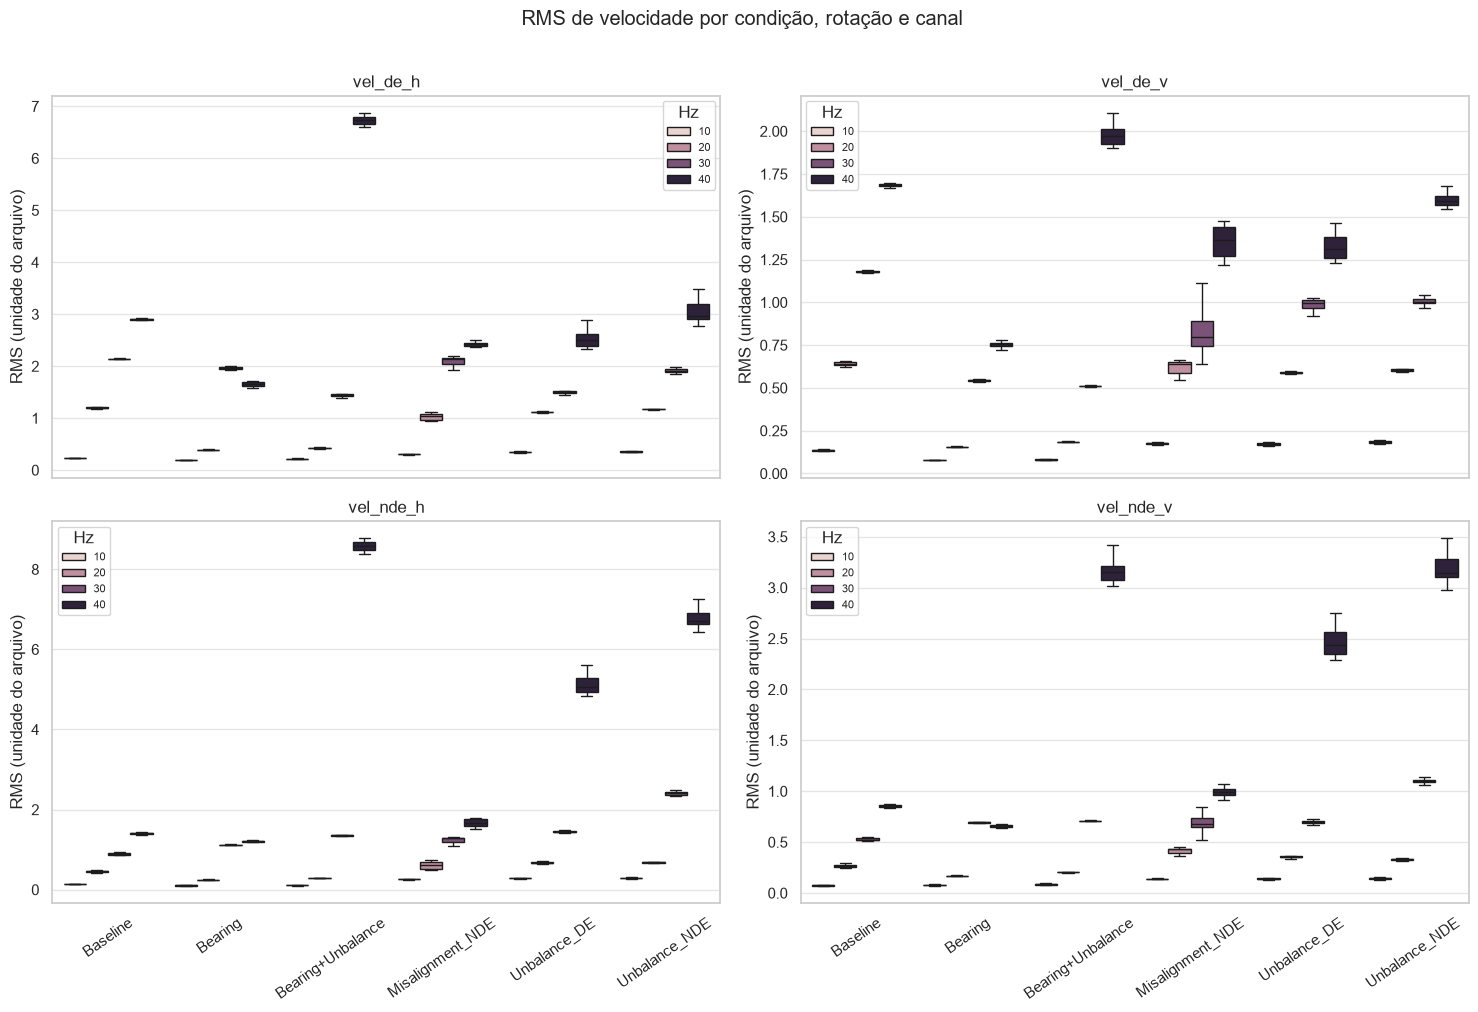

In [11]:
for domain, channels in (("aceleração", ACCELERATION_COLUMNS), ("velocidade", VELOCITY_COLUMNS)):
    fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True)
    for ax, channel in zip(axes.flat, channels):
        sns.boxplot(data=features, x="condition", y=f"{channel}_rms",
                    hue="rotation_hz", hue_order=ROTATIONS_HZ,
                    showfliers=False, ax=ax)
        ax.set_title(channel)
        ax.set_xlabel("")
        ax.set_ylabel("RMS (unidade do arquivo)")
        ax.tick_params(axis="x", rotation=35)
        ax.legend(title="Hz", fontsize=8)
    fig.suptitle(f"RMS de {domain} por condição, rotação e canal", y=1.01)
    fig.tight_layout()
    filename = "acceleration_rms_by_condition.png" if domain == "aceleração" else "velocity_rms_by_condition.png"
    fig.savefig(FIGURE_DIR / filename, dpi=170, bbox_inches="tight")
    plt.show()


In [12]:
rms_by_speed = features.groupby("rotation_hz")[[f"{channel}_rms" for channel in SIGNAL_COLUMNS]].median()
display(rms_by_speed.round(3))
rms_20hz = (features[features.rotation_hz.eq(20)]
            .groupby("condition")["acc_de_h_rms"].median()
            .reindex(CONDITIONS))
display(rms_20hz.rename("RMS mediano acc_de_h a 20 Hz").to_frame().round(3))


,acc_de_h_rms,acc_de_v_rms,acc_nde_h_rms,acc_nde_v_rms,vel_de_h_rms,vel_de_v_rms,vel_nde_h_rms,vel_nde_v_rms
rotation_hz,,,,,,,,
10,0.419,0.213,0.368,0.179,0.269,0.151,0.196,0.114
20,0.976,0.567,0.899,0.441,1.114,0.592,0.489,0.306
30,1.722,0.958,1.374,0.850,1.944,0.951,1.323,0.697
40,2.346,1.528,2.304,1.384,2.846,1.511,3.312,1.700


,RMS mediano acc_de_h a 20 Hz
condition,
Baseline,0.685
Bearing,0.395
Bearing+Unbalance,0.437
Misalignment_NDE,1.719
Unbalance_DE,1.227
Unbalance_NDE,1.334


## 8. Análise espectral: FFT e energia por bandas

A frequência de amostragem é 6 kHz (Nyquist = 3 kHz). O periodograma usa janela Hann e estima RMS em faixas amplas para comparar o conteúdo espectral por classe. Na visualização FFT, linhas tracejadas marcam 1x, 2x e 3x a rotação do exemplo.


,acc_de_h_fft_rms_0_100hz,acc_de_h_fft_rms_100_500hz,acc_de_h_fft_rms_500_1500hz,acc_de_h_fft_rms_1500_3000hz
condition,,,,
Baseline,0.205,0.550,0.343,0.051
Bearing,0.131,0.323,0.168,0.080
Bearing+Unbalance,0.147,0.354,0.180,0.105
Misalignment_NDE,0.143,1.349,1.044,0.234
Unbalance_DE,0.173,1.095,0.527,0.068
Unbalance_NDE,0.191,1.179,0.594,0.072


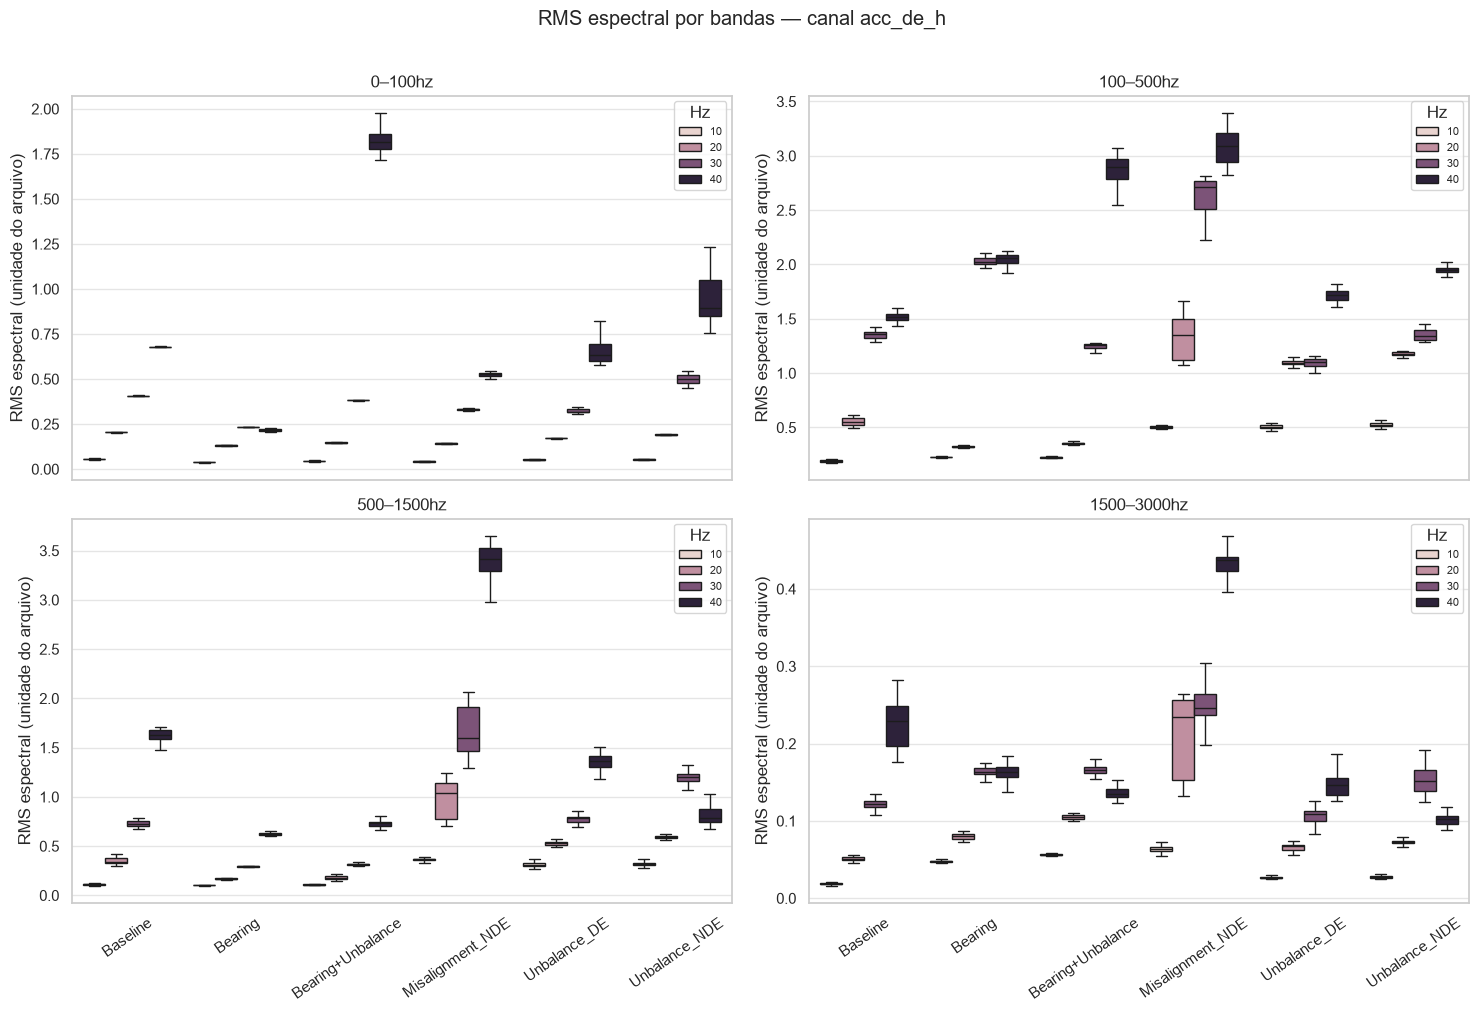

In [13]:
band_columns = [f"acc_de_h_fft_rms_{band}" for band in FREQUENCY_BANDS_HZ]
display(features[features.rotation_hz.eq(20)].groupby("condition")[band_columns].median().reindex(CONDITIONS).round(3))
fig, axes = plt.subplots(2, 2, figsize=(15, 10), sharex=True)
for ax, band in zip(axes.flat, FREQUENCY_BANDS_HZ):
    sns.boxplot(data=features, x="condition", y=f"acc_de_h_fft_rms_{band}",
                hue="rotation_hz", hue_order=ROTATIONS_HZ,
                showfliers=False, ax=ax)
    ax.set_title(band.replace("_", "–"))
    ax.set_xlabel("")
    ax.set_ylabel("RMS espectral (unidade do arquivo)")
    ax.tick_params(axis="x", rotation=35)
    ax.legend(title="Hz", fontsize=8)
fig.suptitle("RMS espectral por bandas — canal acc_de_h", y=1.01)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fft_band_rms_acc_de_h.png", dpi=170, bbox_inches="tight")
plt.show()


## 9. Sinais no tempo e espectros de exemplos

Em cada condição a 20 Hz, selecionamos o arquivo cujo RMS `acc_de_h` está mais próximo da mediana da própria condição. Os exemplos são ilustrativos e não substituem a comparação de todos os arquivos.


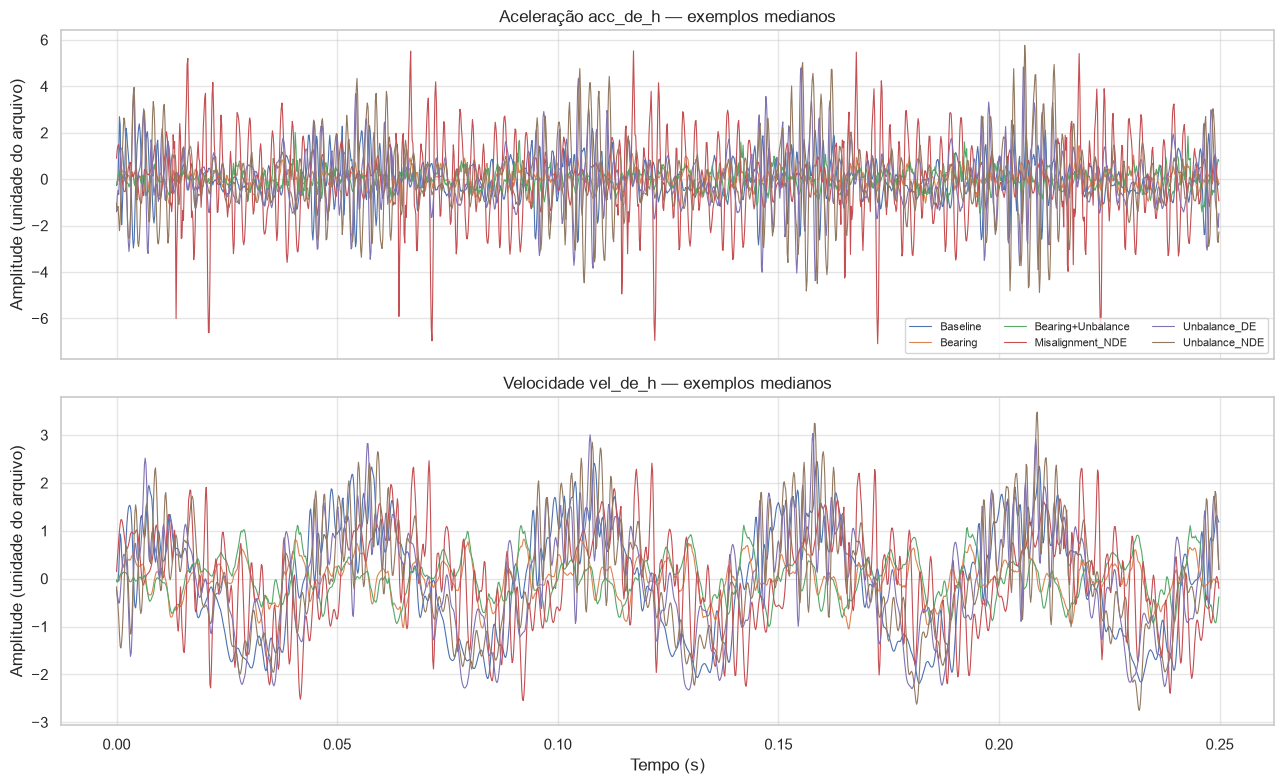

In [14]:
rotation_hz = 20
representatives = []
for condition in CONDITIONS:
    group = features[(features.condition == condition) & (features.rotation_hz == rotation_hz)]
    median_rms = group.acc_de_h_rms.median()
    row = group.loc[(group.acc_de_h_rms - median_rms).abs().idxmin()]
    frame = read_lvm(PROJECT_ROOT / row.relative_path)
    representatives.append((condition, row.file_name, frame))

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
sample_count = int(0.25 * FS_HZ)
time_s = np.arange(sample_count) / FS_HZ
for condition, file_name, frame in representatives:
    axes[0].plot(time_s, frame.acc_de_h.iloc[:sample_count], linewidth=0.8, label=condition)
    axes[1].plot(time_s, frame.vel_de_h.iloc[:sample_count], linewidth=0.8, label=condition)
axes[0].set(title="Aceleração acc_de_h — exemplos medianos", ylabel="Amplitude (unidade do arquivo)")
axes[1].set(title="Velocidade vel_de_h — exemplos medianos", xlabel="Tempo (s)", ylabel="Amplitude (unidade do arquivo)")
axes[0].legend(ncol=3, fontsize=8)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "time_waveforms_20hz.png", dpi=170)
plt.show()


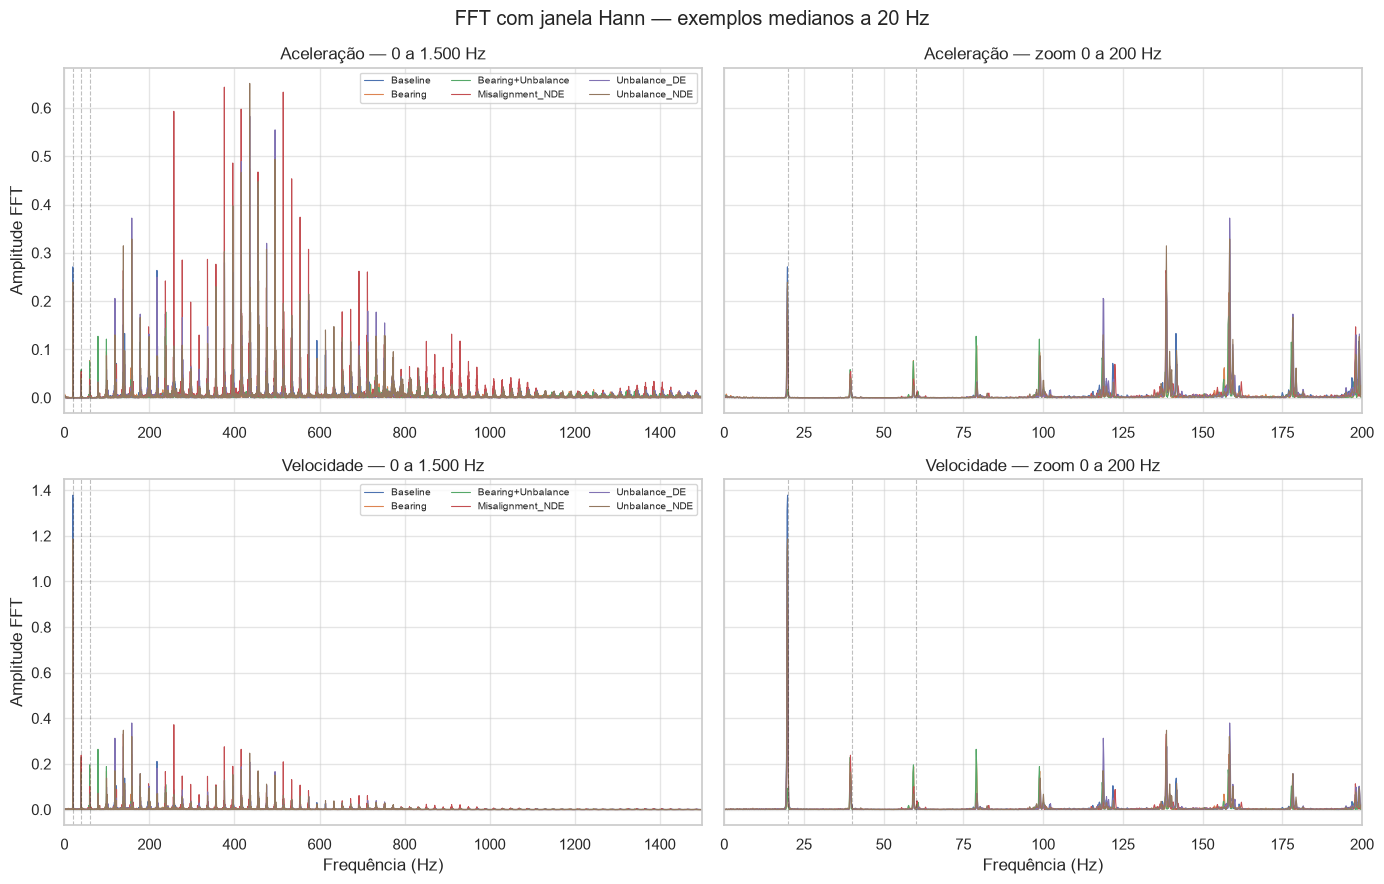

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey="row")
for condition, file_name, frame in representatives:
    for row_index, channel in enumerate(("acc_de_h", "vel_de_h")):
        values = frame[channel].dropna().to_numpy(dtype=float)
        values = values - values.mean()
        window = np.hanning(len(values))
        spectrum = np.fft.rfft(values * window)
        frequency = np.fft.rfftfreq(len(values), d=1 / FS_HZ)
        amplitude = 2 * np.abs(spectrum) / window.sum()
        axes[row_index, 0].plot(frequency, amplitude, linewidth=0.8, label=condition)
        axes[row_index, 1].plot(frequency, amplitude, linewidth=0.8)
for row_index in range(2):
    for harmonic in (rotation_hz, 2 * rotation_hz, 3 * rotation_hz):
        for ax in axes[row_index]:
            ax.axvline(harmonic, color="black", alpha=0.25, linestyle="--", linewidth=0.8)
axes[0, 0].set(xlim=(0, 1500), title="Aceleração — 0 a 1.500 Hz", ylabel="Amplitude FFT")
axes[0, 1].set(xlim=(0, 200), title="Aceleração — zoom 0 a 200 Hz")
axes[1, 0].set(xlim=(0, 1500), title="Velocidade — 0 a 1.500 Hz", xlabel="Frequência (Hz)", ylabel="Amplitude FFT")
axes[1, 1].set(xlim=(0, 200), title="Velocidade — zoom 0 a 200 Hz", xlabel="Frequência (Hz)")
axes[0, 0].legend(ncol=3, fontsize=7)
axes[1, 0].legend(ncol=3, fontsize=7)
fig.suptitle("FFT com janela Hann — exemplos medianos a 20 Hz")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "fft_spectrum_20hz.png", dpi=170)
plt.show()


## 10. Conclusão

Encontramos seis condições com 200 registros cada. Em cada condição há 50 sinais em cada rotação: 10, 20, 30 e 40 Hz. A base, portanto, está equilibrada para essas comparações. Os arquivos têm 36.000 linhas. A aceleração e o trigger estão completos; tempo e velocidade podem terminar antes, como previsto pelo modo de aquisição. Essas ausências ficam no final do sinal, sem buracos no meio.

O achado que mais muda a forma de comparar os sinais é a rotação: quando a máquina gira mais rápido, a vibração também tende a ficar mais forte. Por isso, comparar duas medições em velocidades diferentes pode confundir o efeito da rotação com o efeito de uma falha.

O desalinhamento NDE (Misalignment_NDE: desalinhamento no lado oposto ao acoplamento do motor) é a pista mais evidente até aqui. Por exemplo, no canal horizontal de aceleração do lado acoplado ao motor (acc_de_h; DE significa Drive End, ou lado do acionamento), a 20 Hz (rotação do eixo de 20 ciclos por segundo), o RMS (medida resumida da intensidade da vibração) mediano (valor central entre as medições) foi 0,685 em Baseline (máquina sem falha simulada) e 1,719 em Misalignment_NDE — cerca de 2,5 vezes maior. Já Bearing (falha simulada no rolamento) teve 0,395 nesse mesmo canal. Ou seja, uma falha pode elevar a vibração em certo sinal, enquanto outra pode reduzi-la; não existe uma regra simples de que “mais vibração sempre significa falha”.

Também marcamos 51 arquivos para inspeção por apresentarem valores de RMS atípicos em relação a sinais da mesma condição e rotação. Isso é uma lista de revisão, não uma declaração de que os arquivos estão errados.

### O que ainda não sabemos

Esta análise descreve os dados; ela ainda não treinou nem avaliou um classificador. Sabemos que algumas condições parecem deixar pistas nos sinais, mas ainda precisamos descobrir se essas pistas distinguem as seis condições de maneira confiável. O conjunto representa uma máquina e falhas simuladas, e as unidades físicas precisam ser confirmadas antes de interpretar os valores como limites de operação. A velocidade também foi calculada a partir da aceleração, então esses dois tipos de sinal são relacionados.

### Próximo passo

Revisar os arquivos sinalizados e confirmar as unidades e o contexto experimental. Depois, montar uma comparação de classes que controle a rotação e avalie arquivos separados entre treino e teste. Assim poderemos medir se as pistas vistas nesta EDA realmente ajudam a reconhecer falhas em sinais ainda não analisados.
